In [230]:
# import libraries

import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf
import re
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping


In [231]:
# Load the dataset

df = pd.read_csv('Dataset---Hate-Speech-Detection-using-Deep-Learning.csv') 

In [232]:
# dataset shape

print("Dataset shape:", df.shape)

# column information

df.info()

Dataset shape: (24783, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   class   24783 non-null  int64 
 1   tweet   24783 non-null  object
dtypes: int64(1), object(1)
memory usage: 387.4+ KB


In [233]:
# missing values

print("Missing values:")
print(df.isnull().sum())

# duplicate values

print("Duplicate values:")
print(df.duplicated().sum())


Missing values:
class    0
tweet    0
dtype: int64
Duplicate values:
0


In [234]:
df['class'].value_counts()

class
1    19190
2     4163
0     1430
Name: count, dtype: int64

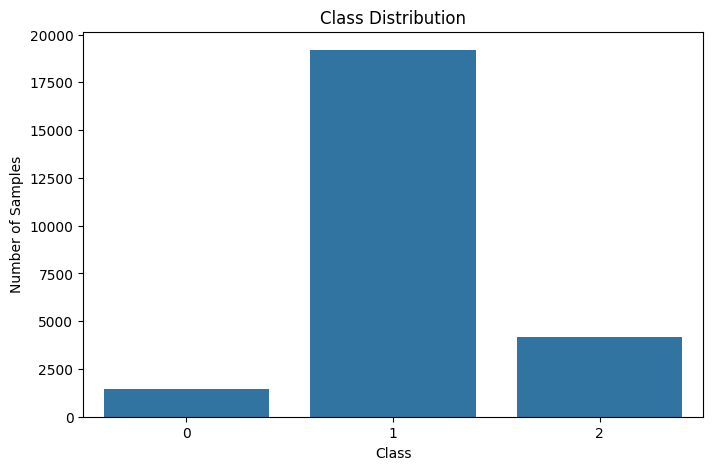

In [235]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='class',
    data=df
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.show()

In [236]:
stop_words = set(stopwords.words('english'))

lemmatizer = WordNetLemmatizer()

In [237]:
# Initialize Lemmatizer and Stop Words
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))


def clean_text(text):
    # Convert to lowercase
    text = str(text).lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Remove numbers
    text = re.sub(r'\d+', '', text)
    
    # Tokenization
    words = text.split()
    
    # Remove stop words
    words = [
        word for word in words 
        if word not in stop_words
    ]
    
    # Lemmatization
    words = [
        lemmatizer.lemmatize(word) 
        for word in words
    ]
    
    return " ".join(words)


# Apply preprocessing
df['cleaned_tweet'] = df['tweet'].apply(clean_text)


# Display before and after cleaning
print("Original Text:")
print(df['tweet'].iloc[0])

print("\nCleaned Text:")
print(df['cleaned_tweet'].iloc[0])

Original Text:
!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up your house. &amp; as a man you should always take the trash out...

Cleaned Text:
rt mayasolovely woman shouldnt complain cleaning house amp man always take trash


In [238]:

tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(df['cleaned_tweet'])

In [239]:
sequences = tokenizer.texts_to_sequences(
    df['cleaned_tweet']
)

In [240]:
print(df['cleaned_tweet'].iloc[0])

print(sequences[0])

rt mayasolovely woman shouldnt complain cleaning house amp man always take trash
[3, 1, 100, 855, 951, 3258, 204, 20, 37, 86, 70, 17]


In [241]:
max_length = 150

X_padded = pad_sequences(
    sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [242]:
X = X_padded
y = df['class']




In [243]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [244]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (19826, 150)
X_test: (4957, 150)
y_train: (19826,)
y_test: (4957,)


In [245]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

In [246]:
class_weight_dict = dict(
    enumerate(class_weights)
)

print(class_weight_dict)

{0: np.float64(5.776806526806527), 1: np.float64(0.4304759423310752), 2: np.float64(1.9845845845845846)}


In [247]:
from tensorflow.keras.layers import Bidirectional


In [248]:
# Build Improved Bidirectional RNN Model

rnn_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=10000,
        output_dim=200
    ),

    Bidirectional(
        SimpleRNN(
            64,
            return_sequences=False
        )
    ),

    Dropout(0.4),

    Dense(
        64,
        activation='relu'
    ),

    Dropout(0.3),

    Dense(
        3,
        activation='softmax'
    )
])







# Early stopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)



In [ ]:
# Compile
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0005
)

rnn_model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


# Summary

rnn_model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 150, 200)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        33,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,042,371 (7.79 MB)

 Trainable params: 2,042,371 (7.79 MB)

 Non-trainable params: 0 (0.00 B)

In [250]:
# Optimizer with lower learning rate

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0005
)


In [251]:
rnn_history = rnn_model.fit(

    X_train,
    y_train,

    epochs=20,

    batch_size=64,

    validation_data=(
        X_test,
        y_test
    ),

    class_weight=class_weight_dict,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/20


310/310 ━━━━━━━━━━━━━━━━━━━━ 17s 48ms/step - accuracy: 0.6123 - loss: 0.9004 - val_accuracy: 0.8249 - val_loss: 0.5469
Epoch 2/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.8042 - loss: 0.5240 - val_accuracy: 0.7948 - val_loss: 0.5477
Epoch 3/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 14s 46ms/step - accuracy: 0.8875 - loss: 0.2776 - val_accuracy: 0.8564 - val_loss: 0.4235
Epoch 4/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9357 - loss: 0.1515 - val_accuracy: 0.8471 - val_loss: 0.4900
Epoch 5/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9612 - loss: 0.0911 - val_accuracy: 0.8378 - val_loss: 0.5514
Epoch 6/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9701 - loss: 0.0717 - val_accuracy: 0.8584 - val_loss: 0.5536


In [252]:
from tensorflow.keras.layers import LSTM

In [253]:



lstm_model = Sequential([

    Input(shape=(max_length,)),

    Embedding(
        input_dim=10000,
        output_dim=200
    ),

    Bidirectional(
        LSTM(
            64,
            return_sequences=False,
            recurrent_dropout=0.2
        )
    ),

    Dropout(0.4),

    Dense(
        64,
        activation='relu'
    ),

    Dropout(0.3),

    Dense(
        3,
        activation='softmax'
    )
])

In [254]:



lstm_model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [255]:
lstm_model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ (None, 150, 200)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 128)            │       135,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,144,131 (8.18 MB)

 Trainable params: 2,144,131 (8.18 MB)

 Non-trainable params: 0 (0.00 B)

In [256]:
lstm_history = lstm_model.fit(

    X_train,
    y_train,

    epochs=20,

    batch_size=64,

    validation_data=(
        X_test,
        y_test
    ),

    class_weight=class_weight_dict,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 84s 260ms/step - accuracy: 0.7476 - loss: 0.7897 - val_accuracy: 0.8184 - val_loss: 0.5650
Epoch 2/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 79s 255ms/step - accuracy: 0.8175 - loss: 0.4726 - val_accuracy: 0.8350 - val_loss: 0.4384
Epoch 3/20
310/310 ━━━━━━━━━━━━━━━━━━━━ 83s 267ms/step - accuracy: 0.8612 - loss: 0.3110 - val_accuracy: 0.8370 - val_loss: 0.4499


In [257]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# RNN Predictions

y_pred_rnn_prob = rnn_model.predict(X_test)

y_pred_rnn = np.argmax(
    y_pred_rnn_prob,
    axis=1
)


# Metrics

rnn_accuracy = accuracy_score(
    y_test,
    y_pred_rnn
)

rnn_precision = precision_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)

rnn_recall = recall_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)

rnn_f1 = f1_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)


print("RNN Results")
print("----------------")
print("Accuracy:", rnn_accuracy)
print("Precision:", rnn_precision)
print("Recall:", rnn_recall)
print("F1-Score:", rnn_f1)


print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_rnn
    )
)
# RNN Predictions


y_pred_rnn_prob = rnn_model.predict(X_test)

y_pred_rnn = np.argmax(
    y_pred_rnn_prob,
    axis=1
)


# Metrics

rnn_accuracy = accuracy_score(
    y_test,
    y_pred_rnn
)

rnn_precision = precision_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)

rnn_recall = recall_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)

rnn_f1 = f1_score(
    y_test,
    y_pred_rnn,
    average='weighted'
)


print("RNN Results")
print("----------------")
print("Accuracy:", rnn_accuracy)
print("Precision:", rnn_precision)
print("Recall:", rnn_recall)
print("F1-Score:", rnn_f1)


print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_rnn
    )
)

155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
RNN Results
----------------
Accuracy: 0.8563647367359289
Precision: 0.8802973022034576
Recall: 0.8563647367359289
F1-Score: 0.8662330327990163

Classification Report
              precision    recall  f1-score   support

           0       0.32      0.51      0.39       286
           1       0.94      0.89      0.91      3838
           2       0.78      0.83      0.81       833

    accuracy                           0.86      4957
   macro avg       0.68      0.74      0.70      4957
weighted avg       0.88      0.86      0.87      4957

155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
RNN Results
----------------
Accuracy: 0.8563647367359289
Precision: 0.8802973022034576
Recall: 0.8563647367359289
F1-Score: 0.8662330327990163

Classification Report
              precision    recall  f1-score   support

           0       0.32      0.51      0.39       286
           1       0.94      0.89      0.91      3838
           2       0.78      0.83      0

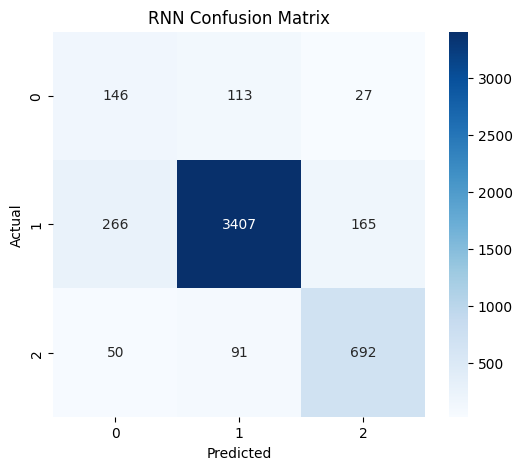

In [258]:
cm_rnn = confusion_matrix(
    y_test,
    y_pred_rnn
)


plt.figure(figsize=(6,5))

sns.heatmap(
    cm_rnn,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("RNN Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [259]:
# LSTM Predictions

y_pred_lstm_prob = lstm_model.predict(X_test)


y_pred_lstm = np.argmax(
    y_pred_lstm_prob,
    axis=1
)


# Metrics

lstm_accuracy = accuracy_score(
    y_test,
    y_pred_lstm
)

lstm_precision = precision_score(
    y_test,
    y_pred_lstm,
    average='weighted'
)

lstm_recall = recall_score(
    y_test,
    y_pred_lstm,
    average='weighted'
)

lstm_f1 = f1_score(
    y_test,
    y_pred_lstm,
    average='weighted'
)


print("LSTM Results")
print("----------------")
print("Accuracy:", lstm_accuracy)
print("Precision:", lstm_precision)
print("Recall:", lstm_recall)
print("F1-Score:", lstm_f1)


print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_lstm
    )
)

155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step
LSTM Results
----------------
Accuracy: 0.8184385717167642
Precision: 0.8998241770005949
Recall: 0.8184385717167642
F1-Score: 0.847834746466608

Classification Report
              precision    recall  f1-score   support

           0       0.23      0.65      0.34       286
           1       0.97      0.82      0.89      3838
           2       0.79      0.88      0.83       833

    accuracy                           0.82      4957
   macro avg       0.67      0.78      0.69      4957
weighted avg       0.90      0.82      0.85      4957



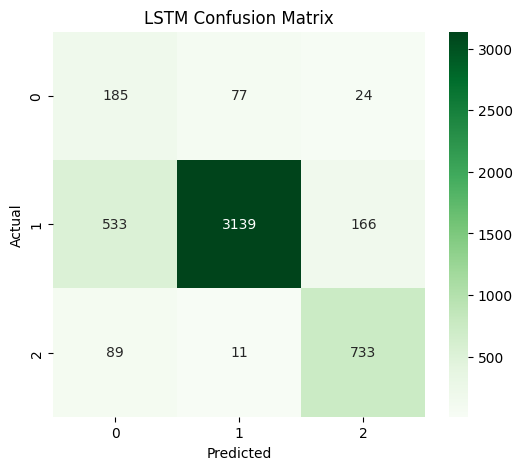

In [260]:
cm_lstm = confusion_matrix(
    y_test,
    y_pred_lstm
)


plt.figure(figsize=(6,5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("LSTM Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [ ]:
import os

os.makedirs("saved_model", exist_ok=True)

rnn_model.save("saved_model/hate_speech_rnn.keras")

In [263]:
import pickle

with open(
    "saved_model/tokenizer.pkl",
    "wb"
) as file:
    pickle.dump(
        tokenizer,
        file
    )